# Instructions

In this notebook you have some problems to solve with Python coding. For each problem, explain your code with comments and explain how it works to solve the problem being addressed. You also MUST include the answers you get from running your code. These instructions may change as needed, so we suggest you read these anew on each homework (we will try to announce ahead if they change).

Collaboration is both allowed and encouraged! Using available resources from your peers is both wise and efficient. While you are welcome to work collaboratively with classmates, that means you can work together to solve problems together, not that one person does the work and others copy it. You are also welcome to use the internet as a resource to refresh your memory, clarify concepts, and help with short code snippets. In order to model good practice, you **MUST** cite your sources **at the time of assignment submission** (we will not accept citations sent after-the-fact), and you should not be copying large portions of code wholesale from any source: internet, human, artificial intelligence, or otherwise.

Things that are off limits:

 -    Soliciting (hey, what did you get for question X? Can you send me your code?) and/or copying code and/or answers from another person.

 -    Using sources appropriately but failing to cite them.

 -     Getting any AI, including ChatGPT, Gemini, or CoPilot to do your work for you.


Before submitting, once you're sure your code is correct, it is recommended that you restart the session kernel under the Runtime/Kernel section and rerun your code with determinism301 to get your final answer to submit. If you have any errors that you suspect might be related to the determinism301 module, you can reference this list https://docs.google.com/document/d/1BdCadBrSKZ1rf29YWzeJ9Eh-UInUqAJZeAJVX79LxRM to see if the problem and solution are in there, and if you still can't solve it then make a private post to instructors on Blackboard.

You **may not** set random_state, seed, or other similar parameters manually for any library unless explicitly instructed, as that will interfere with the reproducibility of your answers. For numpy, you **must** use the old-style ``np.random.uniform``, ``np.random.beta``, and so on distributions instead of ``np.random.default_rng().uniform``, ``np.random.default_rng().beta``, as the latter whave been made to produce stable results, but they will be different from ours which will cause difficulty grading. Using ``numpy.random.RandomState`` is also not allowed for the same reason. We will take off points for **each** problem these are used in, rather than once for the whole assignment.

We would like to make clear that you should read these instructions in full every time. There may be changes in the middle of the semester, and while we will do our best to notify you if anything changes, we are not responsible if there is something included in these instructions that wasn't read.

Note: You **MUST** submit your answers as a Jupyter notebook (.ipynb), otherwise the determinism won't work.

Make sure you include (YOUR NAME, SUBPART) at the start of every code cell, it makes grading significantly easier and can help prevent any mistakes in grading your assignments.

# Import Statements

In [1]:
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Problem 0: Personal Introduction (15 Points)

Write a short self-introduction. This should include your name, major/minors, year in school, previous programming experience, and reason for taking this class (other than it being required for your degree). What do you want to get out of this class and how do you intend to use the skills you will learn here?

In [ ]:
# Write Here:
#
#
#
#
#
#

# Problem 1: Dice Game (35 Points)

## 1a: Creating Dice Class (20 Points)

Create a Python class `DiceClass` to represent a potentially fixed N-sided die. Include a comment at the start of the cell with (YOUR NAME, SUBPART). For example, it might look like ``#(Yanhai Xiong, 1a)``. Make your code as readable as possible and include comments explaining how the code works. It should possess the following attributes:

* `sides`: The number of sides the die has

* `odds`: The chances the die lands on each value; it should be stored as a dictionary as follows:
```py
odds = {
	'1': 0.1
	'2': 0.2
	'3': 0.4
	'4': 0.3
} #Can be longer if more sides are present
```

The class should check that the odds add up to 1 and match what is expected when initialized and raise an error if this is not the case.

It should also possess the following methods:

* `roll`: rolls the die and returns the value, should be able to roll multiple times at once, returning an array of values. The default odds should be those of a fair die (1/N).

To get full credit you must run the test cases below and show the desired functionality. You should also include a short (4-5 sentence) written response discussing how you approached the problem and what, if anything, you found challenging about it.

In [2]:
class DiceClass:
    def __init__(self, sides, odds=None):
        # Check that the number of sides is valid.
        if not isinstance(sides, int) or sides < 1:
            raise ValueError("Number of sides must be a positive integer.")

        self.sides = sides

        # If no odds are provided, create a fair die.
        if odds is None:
            self.odds = {
                str(i): 1 / sides
                for i in range(1, sides + 1)
            }
        else:
            self.odds = odds.copy()

        # Check that the odds contain exactly the expected faces.
        expected_faces = {str(i) for i in range(1, sides + 1)}
        if set(self.odds.keys()) != expected_faces:
            raise ValueError("Odds must match the number of sides.")

        # Check that all probabilities are valid.
        probabilities = list(self.odds.values())
        if any(
            not isinstance(p, (int, float))
            or not np.isfinite(p)
            or p < 0 or p > 1
            for p in probabilities
        ):
            raise ValueError("Probabilities must be between 0 and 1.")

        # Check that the probabilities add up to 1.
        if not np.isclose(sum(probabilities), 1):
            raise ValueError("Probabilities must add up to 1.")

    def roll(self, num=1):
        # Check that the number of rolls is valid.
        if not isinstance(num, int) or num < 1:
            raise ValueError("Number of rolls must be a positive integer.")

        # Generate random outcomes using the specified probabilities.
        results = random.choices(
            population=list(range(1, self.sides + 1)),
            weights=[
                self.odds[str(i)]
                for i in range(1, self.sides + 1)
            ],
            k=num
        )

        # Return the outcomes as a NumPy array.
        return np.array(results)

In [3]:
#Test 1: Normal Die
Dice1 = DiceClass(sides=5,odds={'1':0.1,'2':0.2,'3':0.3,'4':0.2,'5':0.2})
print(Dice1.sides); print(Dice1.odds); print(Dice1.roll(num=10))

5
{'1': 0.1, '2': 0.2, '3': 0.3, '4': 0.2, '5': 0.2}
[3 1 5 3 5 4 1 3 4 2]


In [4]:
#Test 2: No odds entered
Dice2 = DiceClass(sides=20)
print(Dice2.sides); print(Dice2.odds); print(Dice2.roll(num=10))

20
{'1': 0.05, '2': 0.05, '3': 0.05, '4': 0.05, '5': 0.05, '6': 0.05, '7': 0.05, '8': 0.05, '9': 0.05, '10': 0.05, '11': 0.05, '12': 0.05, '13': 0.05, '14': 0.05, '15': 0.05, '16': 0.05, '17': 0.05, '18': 0.05, '19': 0.05, '20': 0.05}
[ 1  9  3 19 15 12 14 11 13 18]


In [5]:
#Test 3: Odds dont match
Dice3 = DiceClass(sides=4, odds={'1':0.1,'2':0.2,'3':0.3,'5':0.2})
print(Dice3.sides); print(Dice3.odds); print(Dice3.roll(num=10))

ValueError: Odds must match the number of sides.

In [6]:
#Test 4: Odds dont add to 1
Dice4 = DiceClass(sides=3, odds={'1':0.5,'2':0.5,'3':0.5})
print(Dice4.sides); print(Dice4.odds); print(Dice4.roll(num=10))

ValueError: Probabilities must add up to 1.

In [ ]:
# WRITE HERE
#
#
#
#

## 1b: Monte Carlo Dice (5 Points)

Roll the two dice initialized below 100,000 times and create a histogram for each of the results. Include all proper graph elements and ensure the figure is readable. Include a comment at the start of the cell with (YOUR NAME, SUBPART). Make your code as readable as possible and include comments explaining how the code works.

Dice:
```py
DiceTest1 = DiceClass(sides=5,odds={'1':0.1,'2':0.3,'3':0.15,'4':0.25,'5':0.2})
DiceTest2 = DiceClass(sides=5,odds={'1':0.2,'2':0.15,'3':0.25,'4':0.3,'5':0.1})
```

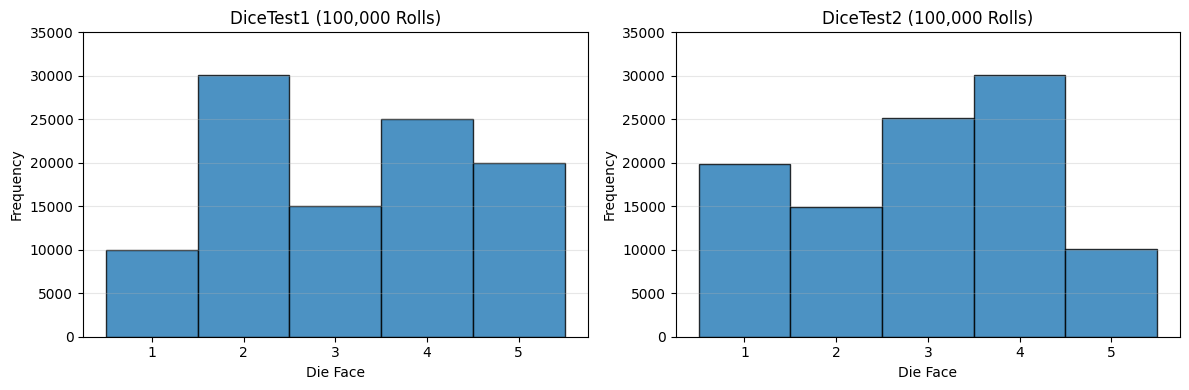

In [8]:
# Initialize two weighted five-sided dice.
DiceTest1 = DiceClass(
    sides=5,
    odds={'1': 0.1, '2': 0.3, '3': 0.15, '4': 0.25, '5': 0.2}
)

DiceTest2 = DiceClass(
    sides=5,
    odds={'1': 0.2, '2': 0.15, '3': 0.25, '4': 0.3, '5': 0.1}
)

# Roll each die 100,000 times.
n_rolls = 100000
results1 = DiceTest1.roll(n_rolls)
results2 = DiceTest2.roll(n_rolls)

# Define bin edges so each integer value has its own bin.
bins = np.arange(0.5, 6.5, 1)

# Create two histograms side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot the results for each die.
for ax, results, title in zip(
    axes,
    [results1, results2],
    ["DiceTest1", "DiceTest2"]
):
    ax.hist(results, bins=bins, edgecolor="black", alpha=0.8)

    # Add graph elements for readability.
    ax.set_title(f"{title} ({n_rolls:,} Rolls)")
    ax.set_xlabel("Die Face")
    ax.set_ylabel("Frequency")
    ax.set_xticks(range(1, 6))
    ax.set_ylim(0, 35000)
    ax.grid(axis="y", alpha=0.3)

# Adjust spacing and display the figure.
plt.tight_layout()
plt.show()


## 1c: Fixed or Fair? (10 Points)

Write a function to roll the dice initialized below N times in M increments (such as N=10 batches of M=10,000 rolls) and return the average roll value for each die for each batch (in that example, there would be 10 values per die). Include a comment at the start of the cell with (YOUR NAME, SUBPART). Run this function for every combination of N = [1,000, 100, 10, 1] and M = [1, 10, 100, 1,000, 10,000]. Plot the average of the returned values for each die as a function of M and add error bars of +/- 1 standard deviation to each point on the plot. Include all proper graph elements and ensure the figure is readable. Make your code as readable as possible and include comments explaining how the code works.

Dice:
```py
DiceTest1 = DiceClass(sides=5,odds={'1':0.1,'2':0.3,'3':0.15,'4':0.25,'5':0.2})
DiceTest2 = DiceClass(sides=5,odds={'1':0.2,'2':0.15,'3':0.25,'4':0.3,'5':0.1})
DiceTest3 = DiceClass(sides=5,odds={'1':0.2,'2':0.2,'3':0.2,'4':0.2,'5':0.2})
```

For full credit, write a short written response (1-2 sentences) on what you see in the plot and how you interpret these results.

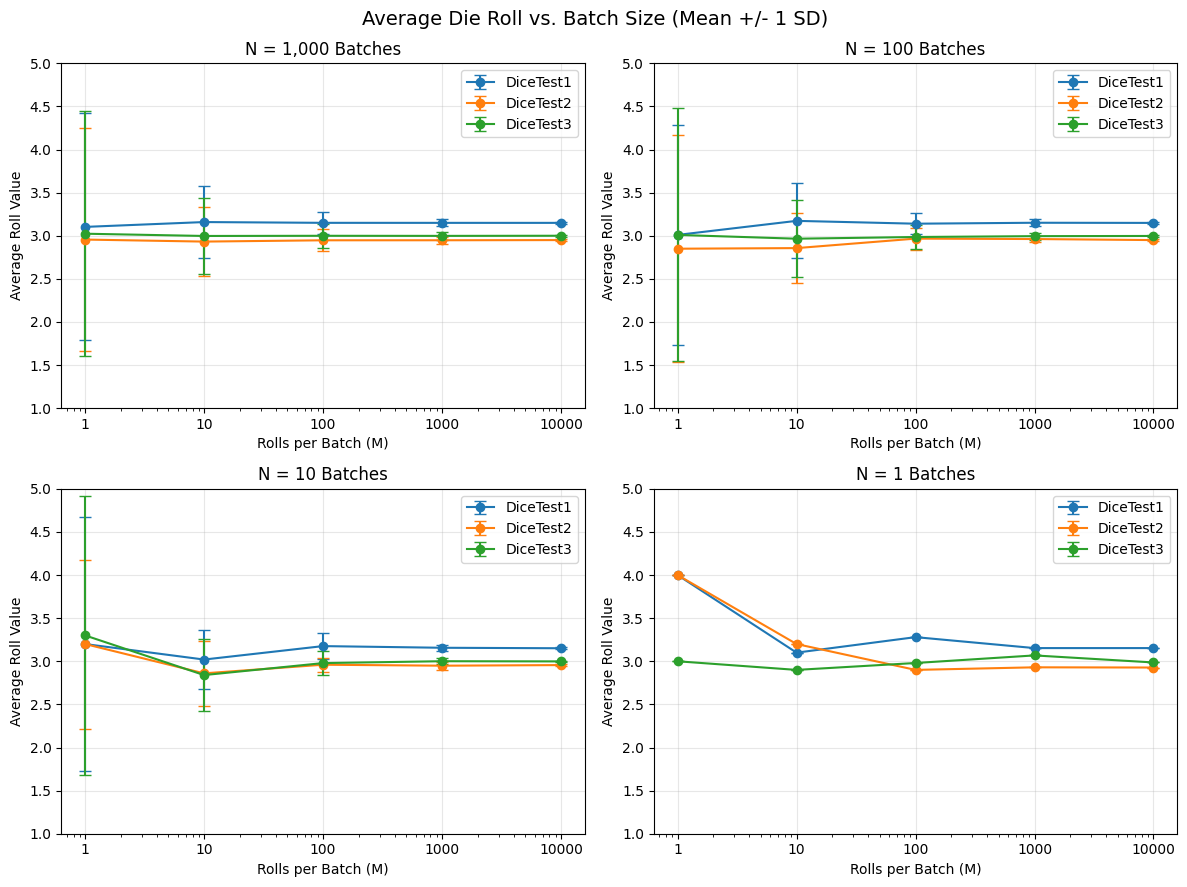

In [9]:
# Initialize three five-sided dice.
DiceTest1 = DiceClass(
    sides=5,
    odds={'1': 0.1, '2': 0.3, '3': 0.15, '4': 0.25, '5': 0.2}
)

DiceTest2 = DiceClass(
    sides=5,
    odds={'1': 0.2, '2': 0.15, '3': 0.25, '4': 0.3, '5': 0.1}
)

DiceTest3 = DiceClass(
    sides=5,
    odds={'1': 0.2, '2': 0.2, '3': 0.2, '4': 0.2, '5': 0.2}
)


# Roll each die N batches of M rolls.
# Return the average roll value for each batch.
def batch_rolls(dice, N, M):
    averages = []

    for i in range(N):
        rolls = dice.roll(M)
        averages.append(np.mean(rolls))

    return np.array(averages)


# Define the numbers of batches and rolls per batch.
N_values = [1000, 100, 10, 1]
M_values = [1, 10, 100, 1000, 10000]

dice = [DiceTest1, DiceTest2, DiceTest3]
dice_names = ["DiceTest1", "DiceTest2", "DiceTest3"]

# Create four plots, one for each N value.
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, N in zip(axes.flat, N_values):

    for die, name in zip(dice, dice_names):
        means = []
        stds = []

        # Run the simulation for each batch size M.
        for M in M_values:
            batch_averages = batch_rolls(die, N, M)

            # Calculate mean and standard deviation
            # across the N batch averages.
            means.append(np.mean(batch_averages))
            stds.append(np.std(batch_averages))

        # Plot the mean with +/- 1 standard deviation.
        ax.errorbar(
            M_values,
            means,
            yerr=stds,
            marker="o",
            capsize=4,
            linewidth=1.5,
            label=name
        )

    # Add graph elements.
    ax.set_title(f"N = {N:,} Batches")
    ax.set_xlabel("Rolls per Batch (M)")
    ax.set_ylabel("Average Roll Value")
    ax.set_xscale("log")
    ax.set_xticks(M_values)
    ax.set_xticklabels([str(m) for m in M_values])
    ax.set_ylim(1, 5)
    ax.grid(True, alpha=0.3)
    ax.legend()

# Add an overall title and adjust spacing.
fig.suptitle(
    "Average Die Roll vs. Batch Size (Mean +/- 1 SD)",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [ ]:
# WRITE HERE
#
#
#
#

# Problem 2: Bayes Theorem (30 Points)

## 2a: Basic Statistics (10 Points)

In a given population of people, 25% of individuals experience joint pain, 8.5% of the population has arthritis, and 85% of those with arthritis experience join pain. Using these statistics, code a Monte Carlo-style Python function that determines the probability that an individual with joint pain has arthritis disease given a number of individuals in the population to scan. Include a comment at the start of the cell with (YOUR NAME, SUBPART). Make your code as readable as possible and include comments explaining how the code works. Run this function for 1,000,000 individuals and report the results (print the percent of individual with arthritis, with joint pain, with arthritis and joint pain, and with joint pain without arthritis).

For full credit, write a short written response (1-2 sentences) on the values you printed out and why they do or don't make sense given the context of the problem.

In [ ]:
def simulate_arthritis(n):
    # Given probabilities
    p_arthritis = 0.085
    p_joint_pain = 0.25
    p_pain_given_arthritis = 0.85

    # Calculate the probability of joint pain without arthritis.
    p_pain_no_arthritis = (
        p_joint_pain - p_arthritis * p_pain_given_arthritis
    ) / (1 - p_arthritis)

    # Simulate whether each individual has arthritis.
    arthritis = np.random.random(n) < p_arthritis

    # Simulate joint pain based on arthritis status.
    joint_pain = np.random.random(n) < np.where(
        arthritis,
        p_pain_given_arthritis,
        p_pain_no_arthritis
    )

    # Calculate the percentages of each group.
    arthritis_pct = np.mean(arthritis) * 100
    pain_pct = np.mean(joint_pain) * 100
    both_pct = np.mean(arthritis & joint_pain) * 100
    pain_only_pct = np.mean(~arthritis & joint_pain) * 100

    # Calculate the conditional probability:
    # P(Arthritis | Joint Pain)
    probability = np.sum(arthritis & joint_pain) / np.sum(joint_pain)

    # Print the simulation results.
    print(f"Individuals with arthritis: {arthritis_pct:.2f}%")
    print(f"Individuals with joint pain: {pain_pct:.2f}%")
    print(f"Individuals with both: {both_pct:.2f}%")
    print(f"Joint pain without arthritis: {pain_only_pct:.2f}%")
    print(f"P(Arthritis | Joint Pain): {probability:.2%}")

    return probability


# Run the Monte Carlo simulation for 1,000,000 individuals.
result = simulate_arthritis(1000000)

Individuals with arthritis: 8.47%
Individuals with joint pain: 24.98%
Individuals with both: 7.21%
Joint pain without arthritis: 17.77%
P(Arthritis | Joint Pain): 28.87%



### Monte Carlo Simulation: Arthritis and Joint Pain

**Goal:** Estimate $P(\text{Arthritis}\mid\text{Joint Pain})$ using Monte Carlo simulation.

**Step 1: Define the known probabilities.**

- $P(A)=0.085$: Probability of having arthritis.
- $P(J)=0.25$: Probability of experiencing joint pain.
- $P(J\mid A)=0.85$: Probability of joint pain given arthritis.

**Step 2: Calculate the missing conditional probability.**

Using the Law of Total Probability:

$$
P(J)=P(J\mid A)P(A)+P(J\mid \neg A)P(\neg A)
$$

Rearranging:

$$
P(J\mid \neg A)=\frac{0.25-0.85(0.085)}{1-0.085}\approx0.1943
$$

**Step 3: Simulate 1,000,000 individuals.**

For each individual, independently generate random numbers to:

1. Determine whether they have arthritis using $P(A)=0.085$.
2. Determine whether they experience joint pain using $P(J\mid A)=0.85$ if they have arthritis, or $P(J\mid\neg A)\approx0.1943$ otherwise.

**Step 4: Estimate probabilities by counting simulated outcomes.**

Calculate the percentages of individuals with arthritis, joint pain, both conditions, and joint pain without arthritis.

Finally, estimate the conditional probability:

$$
P(A\mid J)\approx
\frac{\text{Number with both arthritis and joint pain}}
{\text{Number with joint pain}}
$$

**Expected result:** The simulation should produce approximately $P(A\mid J)=0.289$ (28.9%), with small variations due to randomness.

**Key takeaway:** Monte Carlo simulation estimates conditional probabilities by generating random outcomes according to known probabilities and counting the resulting events. As the sample size increases, the estimates generally approach the theoretical probabilities.


In [ ]:
# WRITE HERE
#
#
#
#

## 2b: Age Considerations (10 Points)

In the same population of people, the ages of the individuals are uniformly distributed from 0-80, but their chances of having arthritis follow a normal distribution with a mean of 70 years and a standard deviation of 15 years (you will need to clip to the 0-80 year range). Code a function to determine these age-dependant chances of an individual having arthritis disease, keeping in mind the average chance across all ages is 8.5%. Include a comment at the start of the cell with (YOUR NAME, SUBPART). Run this function with a sample size of 1,000,000 individuals and plot a histogram of the ages of those with arthritis  (use 20 bins). Print out the proportion of all individuals who have arthritis as well as the most common age of those with arthritis. Make your code as readable as possible and include comments explaining how the code works. NOTE: (if using scipy.stats.norm you may want to look at its methods in the documentation, including the .pdf() method).

Proportion with arthritis: 8.48%
Most common age (bin center): 70.0 years


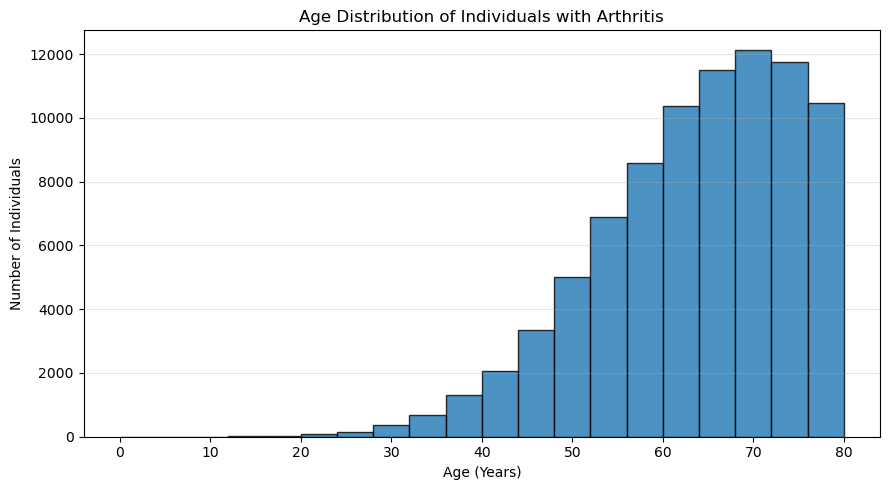

In [ ]:
def simulate_arthritis_by_age(n):
    # Given population statistics
    p_arthritis = 0.085
    mean_age = 70
    std_age = 15

    # Generate uniformly distributed ages between 0 and 80.
    ages = np.random.uniform(0, 80, n)

    # Calculate relative arthritis probabilities using
    # a normal distribution centered at age 70.
    age_weights = stats.norm.pdf(ages, loc=mean_age, scale=std_age)

    # Normalize the probabilities so their average is 8.5%.
    probabilities = age_weights * p_arthritis / np.mean(age_weights)

    # Simulate arthritis status for each individual.
    arthritis = np.random.random(n) < probabilities

    # Extract the ages of individuals with arthritis.
    arthritis_ages = ages[arthritis]

    # Calculate the proportion of individuals with arthritis.
    proportion = np.mean(arthritis)

    # Find the most common age range using 20 histogram bins.
    counts, bin_edges = np.histogram(
        arthritis_ages, bins=20, range=(0, 80)
    )

    most_common_bin = np.argmax(counts)
    most_common_age = (
        bin_edges[most_common_bin] + bin_edges[most_common_bin + 1]
    ) / 2

    # Print results.
    print(f"Proportion with arthritis: {proportion:.2%}")
    print(f"Most common age (bin center): {most_common_age:.1f} years")

    # Plot the age distribution of individuals with arthritis.
    plt.figure(figsize=(9, 5))
    plt.hist(
        arthritis_ages,
        bins=20,
        range=(0, 80),
        edgecolor="black",
        alpha=0.8
    )

    plt.title("Age Distribution of Individuals with Arthritis")
    plt.xlabel("Age (Years)")
    plt.ylabel("Number of Individuals")
    plt.xticks(np.arange(0, 81, 10))
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    return proportion, most_common_age


# Run the simulation for 1,000,000 individuals.
proportion, most_common_age = simulate_arthritis_by_age(1000000)



### Monte Carlo Simulation: Arthritis Probability by Age

**Goal:** Simulate how arthritis prevalence varies with age while maintaining an overall arthritis rate of approximately 8.5%.

**Step 1: Generate a population of 1,000,000 individuals.**

Assume ages are uniformly distributed between 0 and 80:

$$
\text{Age}\sim U(0,80)
$$

**Step 2: Model age-dependent arthritis probabilities.**

Assume the relative likelihood of arthritis follows a Gaussian-shaped curve centered at age 70 with standard deviation 15:

$$
w(a)=\frac{1}{15\sqrt{2\pi}}
\exp\left(-\frac{(a-70)^2}{2(15)^2}\right)
$$

This assigns higher arthritis probabilities to individuals whose ages are closer to 70.

**Step 3: Normalize the probabilities.**

Scale the age-dependent weights so their average equals the target arthritis prevalence of 8.5%:

$$
P(\text{Arthritis}\mid a)
=0.085\frac{w(a)}{\overline{w}}
$$

where $\overline{w}$ is the average weight across all simulated individuals.

**Step 4: Simulate arthritis status.**

For each individual, generate a random number $u\sim U(0,1)$ and assign arthritis if:

$$
u<P(\text{Arthritis}\mid a)
$$

This produces a simulated population in which arthritis probability depends on age.

**Step 5: Analyze the results.**

- **Overall prevalence:** Calculate the proportion of individuals with arthritis. It should be close to 8.5%.
- **Most common age:** Divide ages from 0 to 80 into 20 bins (4 years each) and identify the bin containing the most individuals with arthritis.
- **Visualization:** Plot a histogram showing the age distribution of individuals with arthritis.

**Key takeaway:** Monte Carlo simulation can incorporate demographic factors by assigning different event probabilities to different individuals while preserving a specified overall prevalence.

**Important assumption:** The Gaussian-shaped age dependence and uniform population age distribution are hypothetical modeling choices, not empirical estimates of arthritis prevalence. Also, the Gaussian function provides relative weights rather than probabilities directly; normalization converts these weights into individual probabilities. The resulting probabilities should be checked to ensure they do not exceed 1.


## 2c: Tying it Together (10 Points)

Utilize the code and concepts from the previous two sections to write a function to determine the chance that an individual between the age of 55 and 80 (inclusive), who does not experience joint pain has arthritis (you do not need to explicity use the functions from the previous parts). Include a comment at the start of the cell with (YOUR NAME, SUBPART). Make your code as readable as possible and include comments explaining how the code works. Use 1,000,000 individuals in your general population (ages 0-80). Report your result for this probability and print the percent of individual with arthritis, with joint pain, with arthritis and joint pain, and with joint pain without arthritis from the total population (the probabilities from part a).

To get full credit, You should include a short (4-5 sentence) written response discussing how you approached the problem and what you found challenging about it.

In [ ]:
def simulate_arthritis_joint_pain(n):
    # Given population probabilities
    p_arthritis = 0.085
    p_joint_pain = 0.25
    p_pain_given_arthritis = 0.85

    # Calculate the probability of joint pain without arthritis.
    p_pain_no_arthritis = (
        p_joint_pain - p_arthritis * p_pain_given_arthritis
    ) / (1 - p_arthritis)

    # Generate uniformly distributed ages between 0 and 80.
    ages = np.random.uniform(0, 80, n)

    # Calculate age-dependent arthritis probabilities.
    # Scale the normal PDF so the average probability is 8.5%.
    age_weights = stats.norm.pdf(ages, loc=70, scale=15)
    arthritis_probabilities = (
        age_weights * p_arthritis / np.mean(age_weights)
    )

    # Simulate whether each individual has arthritis.
    arthritis = np.random.random(n) < arthritis_probabilities

    # Assign joint pain probabilities based on arthritis status.
    pain_probabilities = np.where(
        arthritis,
        p_pain_given_arthritis,
        p_pain_no_arthritis
    )

    # Simulate whether each individual experiences joint pain.
    joint_pain = np.random.random(n) < pain_probabilities

    # Select individuals aged 55-80 without joint pain.
    selected = (ages >= 55) & (ages <= 80) & (~joint_pain)

    # Calculate P(Arthritis | Age 55-80, No Joint Pain).
    probability = np.mean(arthritis[selected])

    # Calculate percentages relative to the entire population.
    arthritis_pct = np.mean(arthritis) * 100
    pain_pct = np.mean(joint_pain) * 100
    both_pct = np.mean(arthritis & joint_pain) * 100
    pain_only_pct = np.mean(~arthritis & joint_pain) * 100

    # Print results.
    print(f"Individuals with arthritis: {arthritis_pct:.2f}%")
    print(f"Individuals with joint pain: {pain_pct:.2f}%")
    print(f"Individuals with both: {both_pct:.2f}%")
    print(f"Joint pain without arthritis: {pain_only_pct:.2f}%")

    print(
        f"\nP(Arthritis | Age 55-80, No Joint Pain): "
        f"{probability:.2%}"
    )

    return probability


# Run the simulation for 1,000,000 individuals.
result = simulate_arthritis_joint_pain(1000000)

Individuals with arthritis: 8.51%
Individuals with joint pain: 25.00%
Individuals with both: 7.23%
Joint pain without arthritis: 17.77%

P(Arthritis | Age 55-80, No Joint Pain): 4.85%



### Monte Carlo Simulation: Arthritis, Age, and Joint Pain

**Goal:** Estimate the probability that an individual has arthritis, given that they are between 55 and 80 years old and do not experience joint pain.

**Step 1: Define the known probabilities.**

- $P(A)=0.085$: Overall arthritis prevalence.
- $P(J)=0.25$: Overall joint pain prevalence.
- $P(J\mid A)=0.85$: Probability of joint pain given arthritis.

Using the Law of Total Probability, calculate the probability of joint pain without arthritis:

$$
P(J\mid\neg A)
=\frac{P(J)-P(J\mid A)P(A)}{1-P(A)}
$$

$$
=\frac{0.25-0.85(0.085)}{0.915}\approx0.1943
$$

**Step 2: Generate age-dependent arthritis probabilities.**

Generate 1,000,000 individuals with ages uniformly distributed between 0 and 80.

Assign each individual an arthritis probability proportional to a normal probability density centered at age 70:

$$
w(a)=\text{NormalPDF}(a;\mu=70,\sigma=15)
$$

Normalize these weights to maintain an average arthritis probability of 8.5%:

$$
P(A\mid a)=0.085\frac{w(a)}{\overline{w}}
$$

**Step 3: Simulate arthritis and joint pain.**

For each individual:

1. Randomly determine arthritis status using their age-dependent probability $P(A\mid a)$.
2. Assign a joint pain probability of 85% if they have arthritis, or approximately 19.43% otherwise.
3. Randomly determine whether they experience joint pain.

This creates simulated outcomes in which age influences arthritis risk, while arthritis status influences joint pain risk.

**Step 4: Filter individuals based on the evidence.**

Select individuals who satisfy both conditions:

- Age between 55 and 80.
- No joint pain.

In NumPy, the Boolean mask is:

```python
selected = (ages >= 55) & (ages <= 80) & (~joint_pain)
```

**Step 5: Estimate the conditional probability.**

Among the selected individuals, calculate the proportion who have arthritis:

$$
P(A\mid 55\leq\text{Age}\leq80,\neg J)
\approx
\frac{
\text{Selected individuals with arthritis}
}{
\text{Total selected individuals}
}
$$

This is implemented using:

```python
probability = np.mean(arthritis[selected])
```

**Interpretation:** Older individuals have higher arthritis probabilities under our assumed age model. However, the absence of joint pain reduces the probability of arthritis because 85% of individuals with arthritis are expected to experience joint pain.

**Key takeaway:** Monte Carlo simulation allows us to estimate conditional probabilities involving multiple pieces of evidence by simulating a population and filtering individuals who satisfy the observed conditions.

**Model assumptions:** The age distribution and age-dependent arthritis risk are hypothetical. Joint pain is assumed to depend on arthritis status but not directly on age once arthritis status is known.


In [ ]:
# WRITE HERE
#
#
#
#

# Problem 3: Coin Flip Paradox (20 Points)

## 3a: Basic Coin Flipping (10 Points)

Write a function that flips a fair coin until a specified sequence of flips appears (i.e. "HHH") and then returns the number of flips. Include a comment at the start of the cell with (YOUR NAME, SUBPART). Make your code as readable as possible and include comments explaining how the code works. For full credit, you must run the test cases below:

```py
#Test1: All Heads
print(NumFlips('HHH'))

#Test2: Alternating Pattern
print(NumFlips('THT'))

#Test3: 5 Long Pattern
print(NumFlips('THTHH'))
```

In [ ]:
def NumFlips(pattern):
    # Check that the pattern contains only H and T.
    if not pattern or any(flip not in "HT" for flip in pattern):
        raise ValueError("Pattern must contain only H and T.")

    flips = ""
    count = 0

    # Keep flipping until the target pattern appears.
    while not flips.endswith(pattern):

        # Simulate a fair coin flip.
        flip = random.choice(["H", "T"])

        # Add the new flip to the sequence.
        flips += flip
        count += 1

        # Keep only the most recent flips needed
        # to check for the target pattern.
        flips = flips[-len(pattern):]

    return count


# Test 1: All Heads
print(NumFlips('HHH'))

# Test 2: Alternating Pattern
print(NumFlips('THT'))

# Test 3: 5 Long Pattern
print(NumFlips('THTHH'))


8
7
91


## 3b: Pattern Statistics (10 Points)

Run your function 100 times for all of the possible 3 flip sequences and record the averages for each sequence. Include a comment at the start of the cell with (YOUR NAME, SUBPART). Make your code as readable as possible and include comments explaining how the code works. Make a plot of all of these averages, include all proper graph elements and ensure the figure is readable. For full credit, write a short written response (3-4 sentences) on the results and how you interpret them.

HHH: 12.59 average flips
HHT: 8.42 average flips
HTH: 11.54 average flips
HTT: 7.60 average flips
THH: 8.13 average flips
THT: 10.83 average flips
TTH: 8.16 average flips
TTT: 16.33 average flips


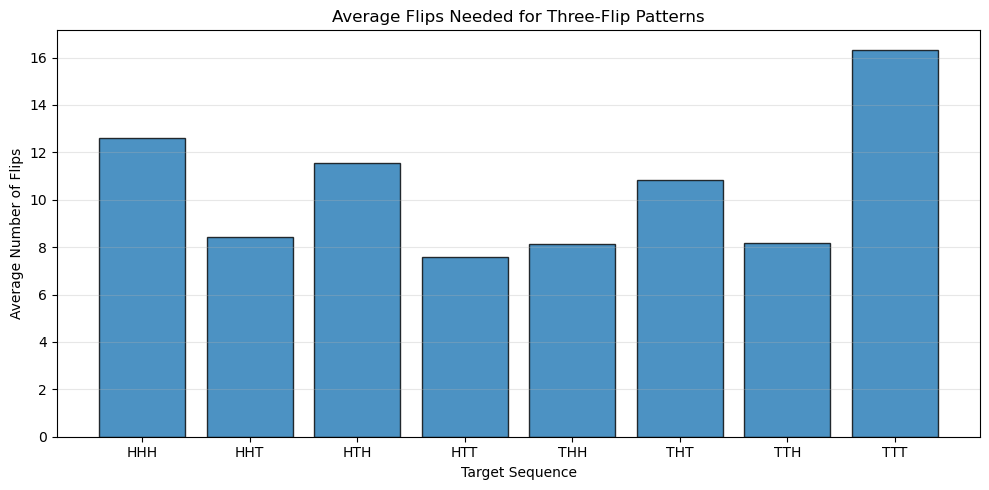

In [ ]:
# Define all possible three-flip sequences.
patterns = [
    "HHH", "HHT", "HTH", "HTT",
    "THH", "THT", "TTH", "TTT"
]

# Number of simulations for each sequence.
n_simulations = 100

# Store the average number of flips for each pattern.
average_flips = []

# Run 100 simulations for each pattern.
for pattern in patterns:
    results = []

    for i in range(n_simulations):
        # Count flips until the pattern appears.
        flips = NumFlips(pattern)
        results.append(flips)

    # Calculate and store the average.
    average = np.mean(results)
    average_flips.append(average)

    print(f"{pattern}: {average:.2f} average flips")

# Plot the average number of flips for each pattern.
plt.figure(figsize=(10, 5))

plt.bar(patterns, average_flips, edgecolor="black", alpha=0.8)

plt.title("Average Flips Needed for Three-Flip Patterns")
plt.xlabel("Target Sequence")
plt.ylabel("Average Number of Flips")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [ ]:
# WRITE HERE
#
#
#
#